# 08 · Twiss Matching: choose quadrupoles for target optics

**Goal:** understand the computation planned for `Twiss_Matching_GUI.py`. **The GUI is still a scaffold:** it lists devices, targets and the number of constraints, but does not compute a matching yet. The ideas below follow the design described in its tooltips; the code is an independent example, not the application's solver.

## Transport of Twiss parameters

In one uncoupled plane, $\Sigma_{out}=R\,\Sigma_{in}R^T$ with $\Sigma=\varepsilon\begin{pmatrix}\beta&-\alpha\\-\alpha&\gamma\end{pmatrix}$, so
$$\beta_{out}=\frac{\Sigma_{out,11}}{\varepsilon},\qquad \alpha_{out}=-\frac{\Sigma_{out,12}}{\varepsilon},$$
and the emittance is conserved by linear transport. The incoming $\varepsilon,\beta,\alpha$ come from an [Emittance Measurement](../tutorials/06_EmittanceMeasurement.ipynb) session, the design model, or manual input.

## Constraints and knobs

Every target value ($\beta_x,\alpha_x,\beta_y,\alpha_y$, or a beam size) is one constraint; every matching quadrupole is one knob. An exact solution needs at least as many knobs as constraints, e.g. **four quadrupoles** for $\beta_x,\alpha_x,\beta_y,\alpha_y$. With fewer knobs the solver can only return the best compromise. The GUI shows this count (*Constraints · Matching quadrupoles*).

## Match quality: Bmag

$$B_{mag}=\tfrac12\left(\beta\gamma_t-2\alpha\alpha_t+\gamma\beta_t\right)\ \ge 1,$$
compares the obtained ellipse $(\beta,\alpha,\gamma)$ with the target $(\beta_t,\alpha_t,\gamma_t)$. $B_{mag}=1$ is a perfect match; after filamentation a mismatched beam grows to $B_{mag}\,\varepsilon$. The planned GUI stops when $B_{mag}-1$ is below a tolerance in both planes.

**Run:** follow [the setup guide](../tutorials/README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from tutorial_support import beam_matrix, transport

incoming = {'x': (beam_matrix(2e-6, 4.0, 0.8), 1), 'y': (beam_matrix(2e-6, 3.0, -0.5), -1)}
drifts = [1.0, 1.0, 1.0, 2.0]
target = {'x': (2.0, 0.0), 'y': (2.0, 0.0)}

def beta_profile(strengths, plane, steps=20):
    sigma, sign = incoming[plane]
    emittance, betas = np.sqrt(np.linalg.det(sigma)), []
    for k, drift in zip(strengths, drifts):
        lens, step = transport(sign * k, drift=0.0), transport(0.0, drift=drift / steps)
        sigma = lens @ sigma @ lens.T
        for _ in range(steps):
            sigma = step @ sigma @ step.T
            betas.append(sigma[0, 0] / emittance)
    return np.array(betas), -sigma[0, 1] / emittance

def bmag(beta, alpha, beta_t, alpha_t):
    return 0.5 * (beta * (1 + alpha_t**2) / beta_t - 2 * alpha * alpha_t + (1 + alpha**2) / beta * beta_t)

def residuals(strengths):
    r = []
    for plane, (beta_t, alpha_t) in target.items():
        betas, alpha = beta_profile(strengths, plane)
        r += [(betas[-1] - beta_t) / beta_t, alpha - alpha_t]
    return np.array(r)

for plane, (beta_t, alpha_t) in target.items():
    betas, alpha = beta_profile(np.zeros(4), plane)
    print(f'Quadrupoles off, plane {plane}: β = {betas[-1]:.2f} m, α = {alpha:.2f}, Bmag = {bmag(betas[-1], alpha, beta_t, alpha_t):.2f}')

Quadrupoles off, plane x: β = 6.25 m, α = -1.25, Bmag = 1.97
Quadrupoles off, plane y: β = 18.42 m, α = -2.58, Bmag = 5.02


## Several solutions: restarts

Matching is nonlinear and usually has several solutions. The planned GUI starts the solver from random quadrupole settings within the limits and keeps the solution with the smallest change from the present settings and the smallest β along the line (**β max**, which keeps the beam away from the aperture). The residuals are scaled, $(\beta-\beta_t)/\beta_t$ and $\alpha-\alpha_t$, so that metres and dimensionless numbers are comparable. The bounds $\pm1.5\ \mathrm{m^{-1}}$ stand for the current limits.

Solution 0: k₁L = [-1.332  1.09  -1.199  0.315] 1/m, change = 2.12, β max = 18.4 m
Solution 1: k₁L = [ 0.965 -1.088  1.263 -0.428] 1/m, change = 1.97, β max = 14.0 m


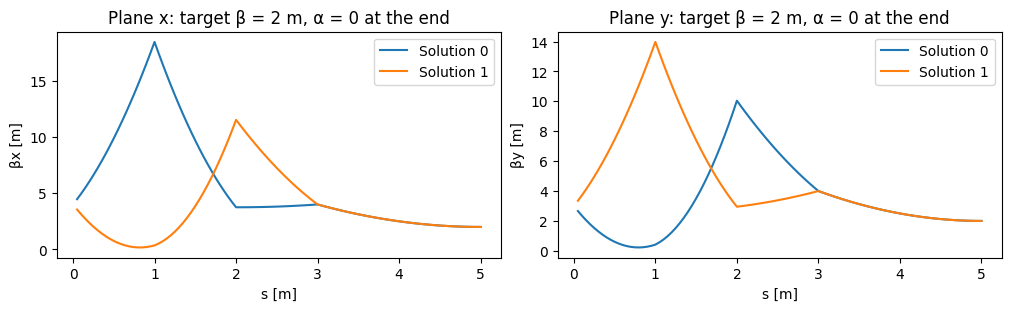

In [2]:
rng = np.random.default_rng(3)
present = np.zeros(4)
solutions = []
for _ in range(40):
    fit = least_squares(residuals, rng.uniform(-1.5, 1.5, 4), bounds=(-1.5, 1.5))
    if fit.cost < 1e-12 and not any(np.allclose(fit.x, s, atol=1e-3) for s in solutions):
        solutions.append(fit.x)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
s = np.cumsum(np.repeat(np.array(drifts) / 20, 20))
for i, strengths in enumerate(solutions):
    beta_max = max(beta_profile(strengths, plane)[0].max() for plane in target)
    print(f'Solution {i}: k₁L = {np.round(strengths, 3)} 1/m, change = {np.linalg.norm(strengths - present):.2f}, β max = {beta_max:.1f} m')
    for ax, plane in zip(axes, target):
        ax.plot(s, beta_profile(strengths, plane)[0], label=f'Solution {i}')
for ax, plane in zip(axes, target):
    ax.set(xlabel='s [m]', ylabel=f'β{plane} [m]', title=f'Plane {plane}: target β = 2 m, α = 0 at the end')
    ax.legend()
plt.show()

Both solutions reach the target exactly, but the one with the smaller β max and the smaller change of settings is preferable.

## Fewer knobs than constraints

With only the first two quadrupoles, four constraints cannot all be met. The least-squares compromise leaves $B_{mag}>1$.

In [3]:
fit = least_squares(lambda k: residuals(np.r_[k, 0.0, 0.0]), np.zeros(2), bounds=(-1.5, 1.5))
for plane, (beta_t, alpha_t) in target.items():
    betas, alpha = beta_profile(np.r_[fit.x, 0.0, 0.0], plane)
    print(f'Two knobs, plane {plane}: β = {betas[-1]:.2f} m, α = {alpha:.2f}, Bmag = {bmag(betas[-1], alpha, beta_t, alpha_t):.3f}')

Two knobs, plane x: β = 10.14 m, α = -1.99, Bmag = 3.024
Two knobs, plane y: β = 6.43 m, α = -0.53, Bmag = 1.807


## Planned workflow and parameters

| GUI element | Planned meaning |
|---|---|
| Quadrupoles (knobs) | Only quadrupoles between the reference point and the target can change the beam at the target. |
| Target location, β/α/σ targets, *Waist*, *Round beam*, *Design Twiss* | Constraints; *Waist* sets α = 0, *Round beam* sets σy = σx. |
| β max | Inequality constraint along the line. |
| Bmag tolerance | Stop when $B_{mag}-1$ is below it in both planes. |
| Restarts, current-change weight | Number of random starts; preference for solutions close to the present settings. |
| Computing method | Linear R-matrix model (fast, starting solution), RF-Track tracking (energy spread, nonlinear effects), online (on the machine, model independent but slow). |
| Apply / Verify / Iterate | Ramp the currents in steps with a transmission check, compare screen sizes with the prediction, and repeat from the new measurement; 2–3 iterations are usually needed because the model is not perfect. |

**Try:** tighten the bounds to ±1.0 and rerun the restarts: no exact solution may remain. Change the target to $\beta_x=\beta_y=1$ m and compare the number of solutions and β max.